# Milestone 15 — uncertainty and failure diagnostics

This notebook extends the team's shared metrics with conditional calibration,
tail misses, discrete-quantile diagnostics and paired SKU comparisons.
All numbers are calculated from genuine saved forecasts. The final holdout is
excluded and no training is performed. See `docs/UNCERTAINTY_ANALYSIS.md`.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'experiment.yaml').exists():
    ROOT = ROOT.parent
assert (ROOT / 'experiment.yaml').exists(), 'Run from repository root or notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.run_uncertainty_analysis import run_analysis
from IPython.display import display, Image

ANALYSIS_DIR = ROOT / 'reports/uncertainty_release'
tables, provenance = run_analysis(
    prediction_paths=[ROOT / 'artifacts/release/development/predictions.parquet'],
    output_dir=ANALYSIS_DIR)
print('Models in this analysis:', provenance['models'])
print('Final holdout evaluated:', provenance['final_holdout_evaluated'])

Models in this analysis: ['deepar', 'kalman', 'lightgbm', 'seasonal_naive']
Final holdout evaluated: False


## Overall accuracy and interval quality

Point-only models have no quantiles. NA means unavailable, not zero.
Compare pinball and width alongside coverage; wider intervals alone can raise coverage.

In [2]:
display(tables['overall'][['model', 'n_observed', 'n_intervals', 'mae', 'pinball_q10', 'pinball_q50', 'pinball_q90', 'coverage_80', 'mean_interval_width_80', 'lower_miss_rate', 'upper_miss_rate']].round(4))

,model,n_observed,n_intervals,mae,pinball_q10,pinball_q50,pinball_q90,coverage_80,mean_interval_width_80,lower_miss_rate,upper_miss_rate
0,deepar,26880,26880,0.9521,0.1214,0.4760,0.3564,0.9149,2.6196,0.0058,0.0793
1,kalman,26880,26880,1.0007,0.1318,0.5004,0.3306,0.8572,2.7626,0.0329,0.1099
2,lightgbm,26880,0,0.9227,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,seasonal_naive,26880,0,1.1869,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Calibration across horizons and training volume

Volume groups use only history available at the origin. They are relative
terciles within the supplied cohort. The same SKU may change group over time.

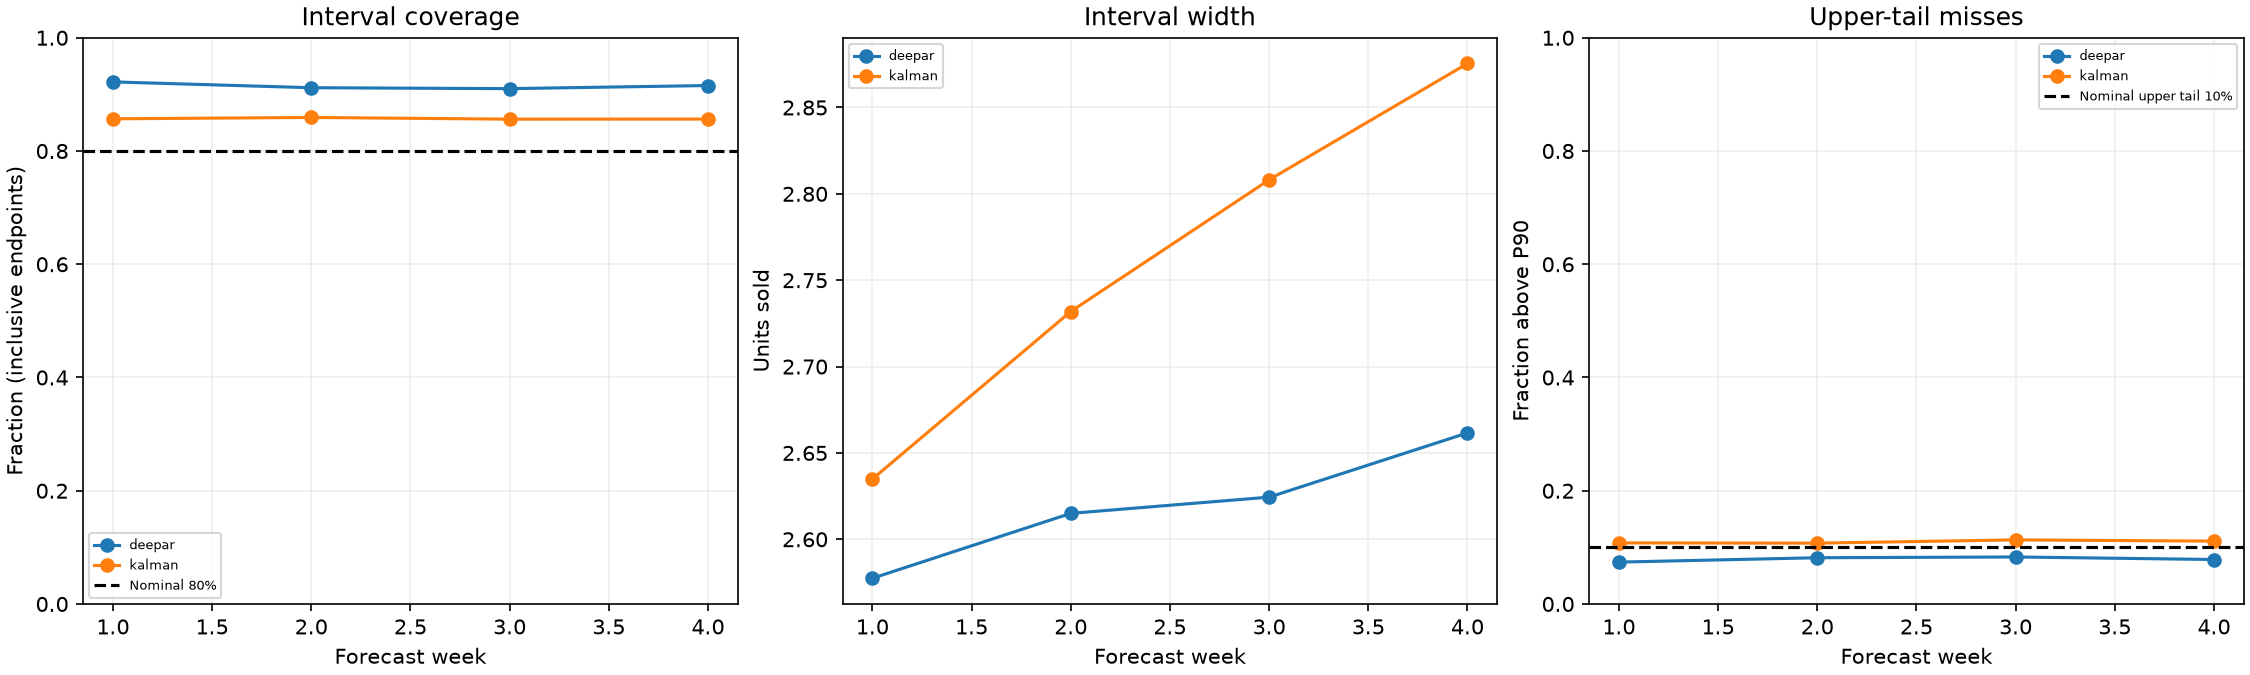

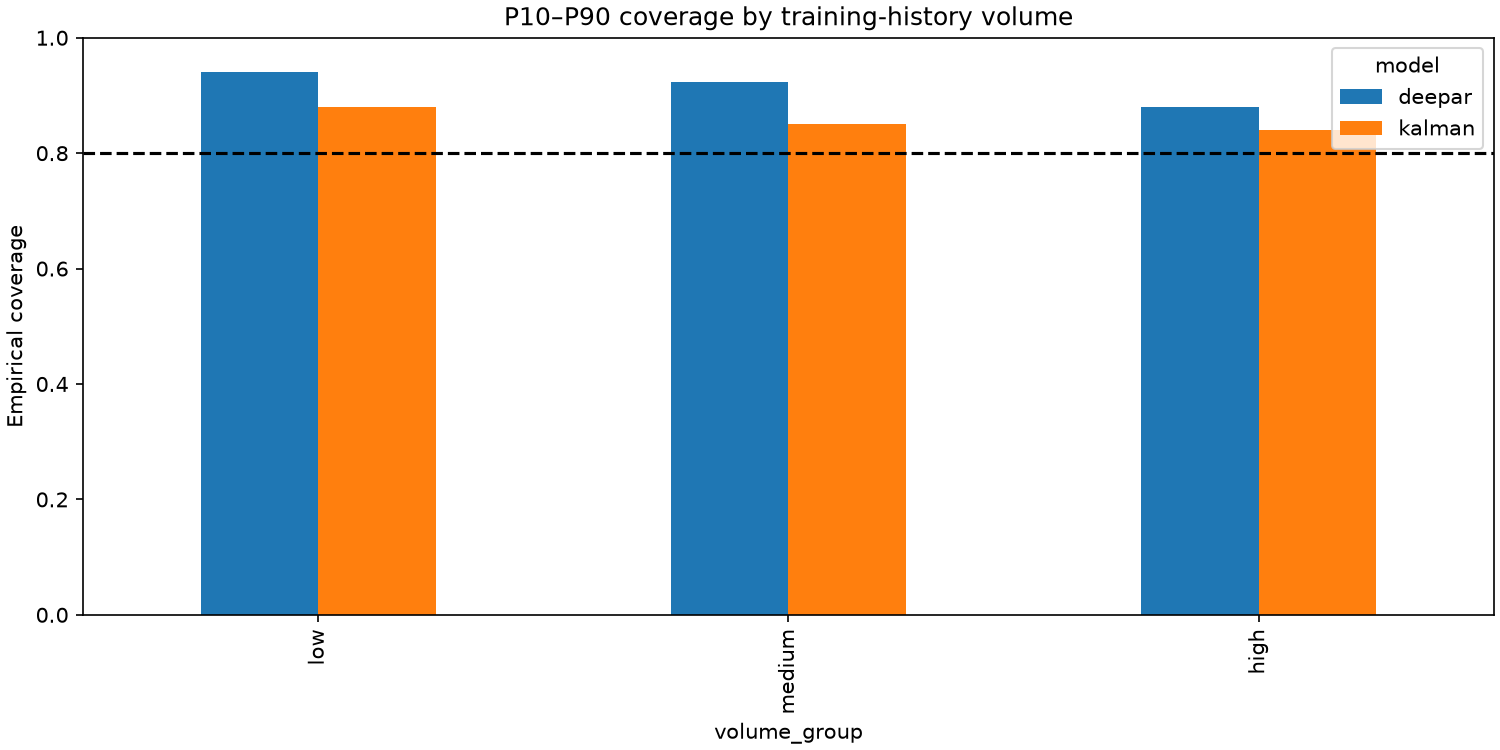

,model,volume_group,horizon_week,n_intervals,coverage_80,mean_interval_width_80
0,deepar,high,1,2240,0.8938,5.0184
1,deepar,high,2,2240,0.8728,5.1080
2,deepar,high,3,2240,0.8679,5.1374
3,deepar,high,4,2240,0.8879,5.2369
4,deepar,low,1,2240,0.9464,0.9270
5,deepar,low,2,2240,0.9402,0.9326
6,deepar,low,3,2240,0.9379,0.9471
7,deepar,low,4,2240,0.9357,0.9355
8,deepar,medium,1,2240,0.9259,1.7869
9,deepar,medium,2,2240,0.9223,1.8045


In [3]:
display(Image(filename=str(ANALYSIS_DIR / 'calibration_by_week.png')))
display(Image(filename=str(ANALYSIS_DIR / 'coverage_by_volume.png')))
display(tables['by_volume_week'][['model', 'volume_group', 'horizon_week', 'n_intervals', 'coverage_80', 'mean_interval_width_80']].round(4))

## Discrete demand and quantile ties

For a valid count quantile q, the target probability can lie between the
fractions with actual strictly below q and actual at or below q. In particular,
zero-heavy sales can make inclusive interval coverage exceed 80%. These
empirical bounds are descriptive and are not an independent-row hypothesis test.

In [4]:
display(tables['overall'][['model', 'q10_cdf_lt', 'q10_cdf_le', 'q50_cdf_lt', 'q50_cdf_le', 'q90_cdf_lt', 'q90_cdf_le']].round(4))

,model,q10_cdf_lt,q10_cdf_le,q50_cdf_lt,q50_cdf_le,q90_cdf_lt,q90_cdf_le
0,deepar,0.0058,0.5831,0.1293,0.6819,0.7423,0.9207
1,kalman,0.0329,0.5845,0.6346,0.6942,0.8901,0.8901
2,lightgbm,NaN,NaN,NaN,NaN,NaN,NaN
3,seasonal_naive,NaN,NaN,NaN,NaN,NaN,NaN


## Where models fail and which model wins per SKU

All pairs share exact forecast keys and canonical actuals. Negative MAE
differences favor model A. Ties are explicit. Worst-series tables identify
candidates for inspection, not causal explanations of model errors.

In [5]:
display(tables['paired_series'].groupby(['model_a', 'model_b', 'winner']).size().rename('series_count').to_frame())
display(tables['worst_series'][['model', 'series_id', 'mae', 'coverage_80', 'upper_miss_rate']].round(4))
display(tables['history_labels'].head(10))

series_count
model_a  model_b        winner                      
deepar   kalman         deepar                   178
                        kalman                    62
         lightgbm       deepar                   122
                        lightgbm                 100
                        tie                       18
         seasonal_naive deepar                   208
                        seasonal_naive            15
                        tie                       17
kalman   lightgbm       kalman                    43
                        lightgbm                 197
         seasonal_naive kalman                   166
                        seasonal_naive            74
lightgbm seasonal_naive lightgbm                 221
                        seasonal_naive             7
                        tie                       12

,model,series_id,mae,coverage_80,upper_miss_rate
0,deepar,FOODS_3_682__WI_3,9.5804,0.5000,0.4732
1,deepar,FOODS_3_760__CA_4,6.1161,0.4554,0.5357
2,deepar,HOUSEHOLD_1_234__WI_2,5.5134,0.6161,0.2589
3,deepar,HOUSEHOLD_1_427__WI_2,4.3438,0.7143,0.0625
4,deepar,FOODS_3_351__CA_3,4.2589,0.8036,0.0893
5,deepar,HOBBIES_1_370__CA_2,4.0045,0.9286,0.0714
6,deepar,HOUSEHOLD_1_453__CA_3,3.9286,0.6518,0.3482
7,deepar,FOODS_3_086__CA_1,3.8616,0.9196,0.0268
8,deepar,HOUSEHOLD_1_327__CA_1,3.4464,0.8214,0.1518
9,deepar,HOUSEHOLD_1_198__WI_1,3.3125,0.7500,0.1696


,series_id,origin,volume_group,history_mean,history_observed,history_zero_fraction,trailing_zero_days
0,FOODS_1_004__TX_2,1801,high,7.174903,1801,0.335369,0
28,FOODS_1_019__WI_1,1801,high,3.516935,1801,0.275958,0
56,FOODS_1_026__CA_2,1801,high,0.764575,1801,0.573015,57
84,FOODS_1_038__WI_2,1801,medium,0.369239,1801,0.734037,0
112,FOODS_1_056__WI_2,1801,low,0.145475,1801,0.898390,74
140,FOODS_1_076__CA_4,1801,medium,0.730705,1801,0.554137,27
168,FOODS_1_102__CA_4,1801,medium,0.421433,1801,0.705719,300
196,FOODS_1_105__TX_3,1801,medium,0.362021,1801,0.785675,312
224,FOODS_1_111__TX_3,1801,low,0.025541,1801,0.976680,23
252,FOODS_1_150__WI_3,1801,medium,0.671849,1801,0.604109,0


## Limits and further experiments

The frozen release supplies genuine DeepAR forecasts on the same four-origin
forecast grid as the other methods. These development diagnostics include
selection-stage windows. The separate final benchmark is recorded under
`artifacts/release/final/`; this notebook does not rerun final fitting or scoring.
Zero sales do not establish stockouts, and outcomes concern observed sales
rather than latent demand. Correlated series and origins limit inference from
these descriptive summaries.